# 05 — Noise & Outlier

Mục tiêu: lượng hoá nhiễu và outlier trên dữ liệu thô, trước khi làm sạch.
1. Outlier tốc độ / gia tốc, các "spike" nhảy toạ độ (A → B xa → A).
2. Mức dao động GPS khi đứng yên (jitter).


In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from utils import add_geo, add_kinematics, haversine, load_points, savefig, setup_style

setup_style()
pts = load_points(["user", "traj_id", "lat", "lon", "ts_utc"])
pts = pts[pts.lat.between(-90, 90)]  # bỏ 1 điểm lat lỗi (xem NB01)
pts = pts[pts.ts_utc.dt.year >= 2007]
pts = add_geo(pts)
n0 = len(pts)
pts = pts.sort_values(["user", "ts_utc"], kind="stable").drop_duplicates(["user", "ts_utc"]).reset_index(drop=True)
print(f"Bỏ {n0 - len(pts):,} điểm trùng timestamp → còn {len(pts):,}")
pts["traj_key"] = pts.user.astype(str) + "_" + pts.traj_id.astype(str)
pts = add_kinematics(pts)

Bỏ 698,900 điểm trùng timestamp → còn 24,178,074


## 1. Outlier tốc độ & gia tốc

In [2]:
v = pts.speed_kmh.dropna()
thr = [100, 200, 300, 500, 1000]
pd.DataFrame({"n": [(v > t).sum() for t in thr], "%": [(v > t).mean() * 100 for t in thr]}, index=[f"> {t} km/h" for t in thr])

,n,%
> 100 km/h,1305501,5.4037
> 200 km/h,88554,0.3665
> 300 km/h,53453,0.2213
> 500 km/h,49103,0.2032
> 1000 km/h,1749,0.0072


In [3]:
pts["acc"] = pts.groupby("traj_key", observed=True).speed_kmh.diff() / 3.6 / pts.dt_s
a = pts.acc.abs().dropna()
print(a.describe(percentiles=[.5, .9, .99, .999]))
print(f"% điểm |gia tốc| > 5 m/s²: {(a > 5).mean():.3%}  | > 10 m/s²: {(a > 10).mean():.3%}")

count   24,140,736.0000
mean             4.2412
std          1,263.6676
min              0.0000
50%              0.1817
90%              0.8826
99%              3.5987
99.9%           17.3099
max        861,504.9536
Name: acc, dtype: float64
% điểm |gia tốc| > 5 m/s²: 0.644%  | > 10 m/s²: 0.242%


In [4]:
# Spike A→B→A: tốc độ vào & ra đều rất lớn nhưng điểm trước và sau lại gần nhau
k = pts.traj_key.to_numpy()
same_prev = np.r_[False, k[1:] == k[:-1]]
same_next = np.r_[k[1:] == k[:-1], False]
v_in = pts.speed_kmh.to_numpy()
v_out = np.r_[v_in[1:], np.nan]
lat, lon = pts.lat.to_numpy(), pts.lon.to_numpy()
d_skip = np.r_[np.nan, haversine(lat[:-2], lon[:-2], lat[2:], lon[2:]), np.nan]
d_in = pts.dist_m.to_numpy()
spike = same_prev & same_next & (v_in > 150) & (v_out > 150) & (d_skip < 0.3 * d_in)
pts["spike"] = spike
print(f"Spike A→B→A: {spike.sum():,} điểm, ở {pts.loc[spike, 'traj_key'].nunique():,} trajectory, {pts.loc[spike, 'user'].nunique()} user")
print("Khoảng nhảy (km) của spike:")
print((pts.loc[spike, "dist_m"] / 1000).describe(percentiles=[.5, .9, .99]))

Spike A→B→A: 710 điểm, ở 109 trajectory, 48 user
Khoảng nhảy (km) của spike:
count   710.0000
mean    711.8898
std     316.6724
min       0.0432
50%     856.6820
90%     861.6821
99%     861.9859
max     862.0038
Name: dist_m, dtype: float64


In [5]:
# Spike nhảy tới đâu? Nếu nhiều spike rơi vào cùng 1 toạ độ → toạ độ "mặc định" của thiết bị/firmware, không phải nhiễu ngẫu nhiên
sp = pts.loc[spike]
print(sp.assign(lat_r=sp.lat.round(2), lon_r=sp.lon.round(2)).groupby(["lat_r", "lon_r"])
      .agg(n=("user", "size"), users=("user", "nunique"), first=("ts_utc", "min"), last=("ts_utc", "max"))
      .sort_values("n", ascending=False).head(10))

                   n  users               first                last
lat_r   lon_r                                                      
40.0100 116.3200  12      7 2008-06-19 23:52:28 2009-07-11 07:38:01
39.7800 116.1800  11      1 2008-09-26 09:18:08 2008-09-26 09:18:58
34.2900 109.0000  10      1 2008-09-26 09:32:31 2008-09-26 09:33:16
39.7900 116.1900  10      1 2008-09-26 09:17:13 2008-09-26 09:17:58
39.8100 116.1700  10      1 2008-09-26 09:15:13 2008-09-26 09:15:58
34.3400 109.1100  10      1 2008-09-26 09:24:21 2008-09-26 09:25:06
34.2900 108.9900  10      1 2008-09-26 09:33:22 2008-09-26 09:34:08
34.3200 109.0800   9      1 2008-09-26 09:26:41 2008-09-26 09:27:21
39.8200 116.1600   9      1 2008-09-26 09:14:23 2008-09-26 09:15:03
34.3000 109.0200   9      1 2008-09-26 09:30:56 2008-09-26 09:31:36


**Insight:** phần lớn spike (~860 km) đến từ **1 trajectory ngày 2008-09-26**, toạ độ nhảy qua lại liên tục giữa Bắc Kinh (39.8N 116.2E)
và Tây An (34.3N 109.0E) mỗi vài giây → giống 2 luồng vị trí bị trộn (2 thiết bị / file ghép), không phải nhiễu ngẫu nhiên.
Loại lỗi này cần phát hiện ở mức **trajectory** (tỉ lệ spike cao → loại cả file), không chỉ ở mức điểm.

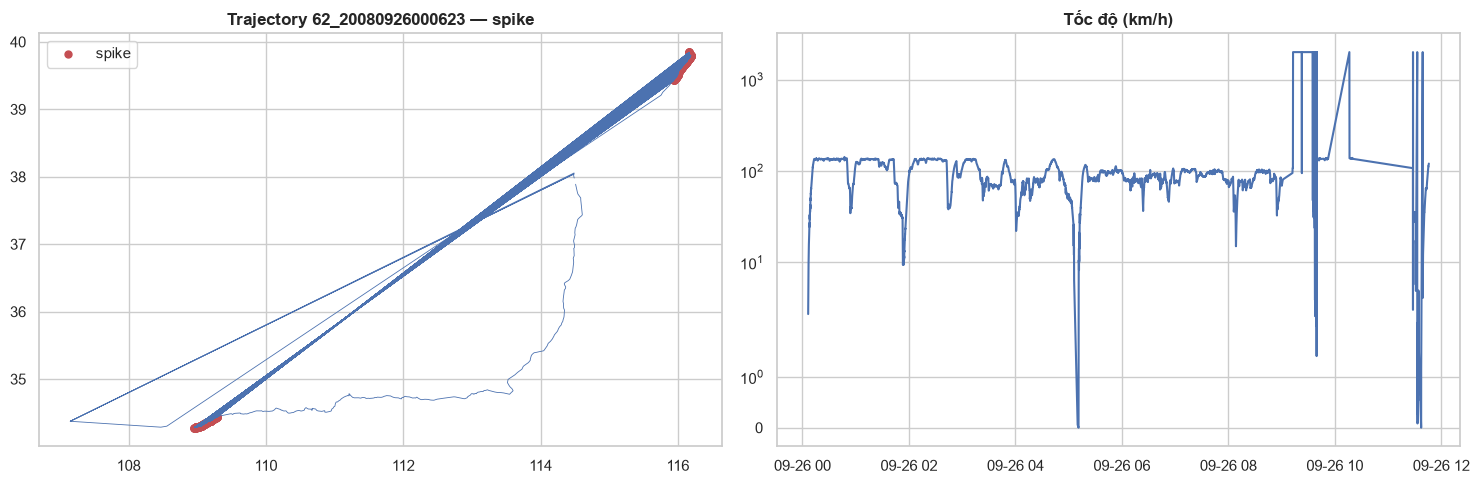

In [6]:
# Ví dụ 1 trajectory có spike lớn
ex = pts.loc[spike].sort_values("dist_m", ascending=False).traj_key.iloc[0]
g = pts[pts.traj_key == ex]
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].plot(g.lon, g.lat, "-", lw=0.6); ax[0].scatter(g.loc[g.spike, "lon"], g.loc[g.spike, "lat"], c="r", s=25, label="spike")
ax[0].legend(); ax[0].set_title(f"Trajectory {ex} — spike")
ax[1].plot(g.ts_utc, g.speed_kmh.clip(upper=2000)); ax[1].set_yscale("symlog"); ax[1].set_title("Tốc độ (km/h)")
plt.tight_layout(); savefig("05_spike_example"); plt.show()

**Insight:** outlier tốc độ ít về tỉ lệ nhưng biên độ cực lớn (nhảy hàng chục – hàng trăm km), làm sai quãng đường và có thể
tạo stay-point giả. Lọc theo tốc độ đơn thuần sẽ xoá nhầm điểm hợp lệ *sau* spike → nên dùng kiểm tra **A→B→A** (hoặc median filter) rồi
tính lại tốc độ; ngưỡng tốc độ ngoài máy bay ~ 300–400 km/h.

## 2. Jitter khi đứng yên
Lấy các cửa sổ 10 phút mà quãng đường tổng < 100 m liên tục... đơn giản hơn: các đoạn có tốc độ trung vị < 1 km/h, đo bán kính phân tán.

13,236 cửa sổ 10' đứng yên
              p50         p90          mx
count 13,236.0000 13,236.0000 13,236.0000
mean       8.8756     46.0993     70.0888
std       24.3049    147.1716    206.0898
min        0.0000      0.0000      0.0000
50%        4.8069     16.2791     24.4000
75%        9.4026     32.0231     46.4327
90%       16.4470     71.3264    112.6444
95%       24.5461    148.8777    258.8245
99%       79.3282    745.9422  1,080.0416
max      840.1293  4,367.1537  5,387.6950


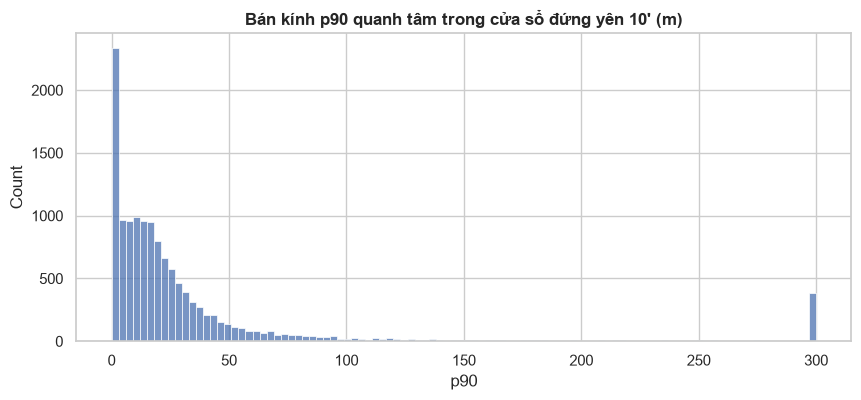

In [7]:
pts["win"] = pts.ts_utc.dt.floor("10min")
w = pts[pts.dt_s <= 10].groupby(["traj_key", "win"], observed=True).agg(
    n=("lat", "size"), v_med=("speed_kmh", "median"), lat_c=("lat", "median"), lon_c=("lon", "median"))
w = w[(w.n >= 30) & (w.v_med < 1)]
tmp = pts.join(w[["lat_c", "lon_c"]], on=["traj_key", "win"], how="inner")
tmp["r"] = haversine(tmp.lat, tmp.lon, tmp.lat_c, tmp.lon_c)
jit = tmp.groupby(["traj_key", "win"], observed=True).r.agg(p50="median", p90=lambda s: s.quantile(.9), mx="max")
print(f"{len(jit):,} cửa sổ 10' đứng yên")
print(jit.describe(percentiles=[.5, .75, .9, .95, .99]))
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(jit.p90.clip(upper=300), bins=100, ax=ax); ax.set_title("Bán kính p90 quanh tâm trong cửa sổ đứng yên 10' (m)")
savefig("05_jitter"); plt.show()

**Insight:** khi đứng yên, phần lớn điểm nằm trong vài chục mét quanh tâm, nhưng đuôi dài (indoor/multipath → hàng trăm m).
